# COU 07506 Digital Signal Processing — Week 01
## Lab 0: Setting Up the DSP Laboratory

**Name:** SHEMSA NASSOR AMIN  
**Registration No.:** 240242454734  
**Class:** BEng24COE  
**Group:** 16  
**Date revised:** 26 November 2026  
**Instructor:** Dr. Haji Fimbombaya  
**Repository:** [Shemsanofly/COU07506-labs](https://github.com/Shemsanofly/COU07506-labs)  
**Reference:** COU07506_DSP_Laboratory_Manual_2026-27.pdf, Week 1.

Instructor checkpoint: [ ] Checkpoint 1 (instructor to confirm).

## Pre-lab

| Device | Signal processed | DSP operation |
| --- | --- | --- |
| Smartphone | Microphone speech | Noise reduction during calls |
| Laptop | Microphone audio | Echo cancellation during online meetings |
| Bluetooth headphones | Digital audio | Equalization before playback |

## Task 1.1 - Elementary sequences

The four sequences are plotted for $-5 \leq n \leq 10$.
Their amplitudes are dimensionless, and $n$ is the sample index.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from pathlib import Path
from IPython.display import Audio, display

plt.rcParams['figure.figsize'] = (9, 3.5)
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)

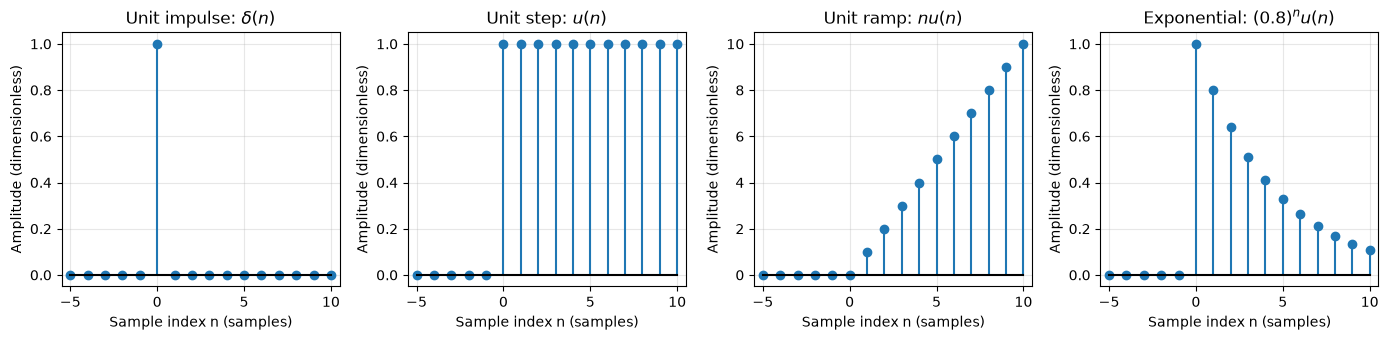

Known-value checks passed for all four sequences.


In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)       # 1 only at n = 0
step = (n >= 0).astype(float)        # 1 for every n >= 0
ramp = n * step                     # n for n >= 0, otherwise 0
expo = 0.8**n * step                # causal, decaying exponential

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, x_sequence, title in zip(
    axes,
    [delta, step, ramp, expo],
    [r'Unit impulse: $\delta(n)$', r'Unit step: $u(n)$',
     r'Unit ramp: $n u(n)$', r'Exponential: $(0.8)^n u(n)$'],
):
    ax.stem(n, x_sequence, basefmt='k-')
    ax.set_title(title)
    ax.set_xlabel('Sample index n (samples)')
    ax.set_ylabel('Amplitude (dimensionless)')
    ax.set_xlim(-5.5, 10.5)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_1_sequences.png', dpi=160)
plt.show()

assert delta.sum() == 1 and delta[n == 0].item() == 1
assert np.all(step[n < 0] == 0) and np.all(step[n >= 0] == 1)
assert ramp[n == 10].item() == 10
assert np.isclose(expo[n == 1].item(), 0.8)
print('Known-value checks passed for all four sequences.')

The impulse has only one nonzero sample at $n=0$. The step changes from 0
to 1 at $n=0$. The ramp increases by 1 per sample for $n\geq0$. The
exponential starts at 1 and decreases by a factor of 0.8 each sample.
All four are zero for $n<0$.

## Task 1.2 - Changing the parameters

### Exponentials: $a^n u(n)$

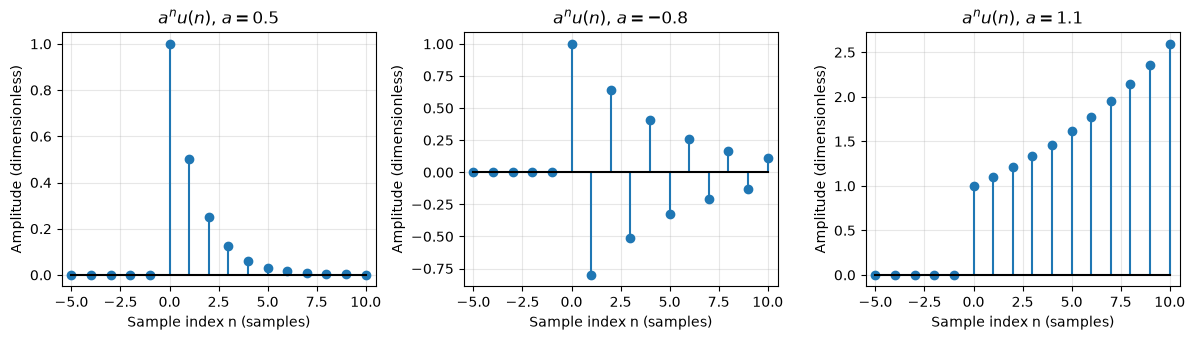

a =  0.5: x(0) = 1, x(1) = 0.5, x(10) = 0.000977
a = -0.8: x(0) = 1, x(1) = -0.8, x(10) = 0.107374
a =  1.1: x(0) = 1, x(1) = 1.1, x(10) = 2.593742


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    xa = a**n * step
    ax.stem(n, xa, basefmt='k-')
    ax.set_title(fr'$a^n u(n)$, $a={a}$')
    ax.set_xlabel('Sample index n (samples)')
    ax.set_ylabel('Amplitude (dimensionless)')
    ax.set_xlim(-5.5, 10.5)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_2_exponentials.png', dpi=160)
plt.show()

for a in [0.5, -0.8, 1.1]:
    print(f'a = {a:4.1f}: x(0) = 1, x(1) = {a:.1f}, x(10) = {a**10:.6f}')

- $a=0.5$: positive samples decay rapidly toward zero.
- $a=-0.8$: the sign alternates while the magnitude decays toward zero.
- $a=1.1$: positive samples grow without bound as $n$ increases. The short
  plot shows the beginning of this growth.

### Cosines for $0\leq n\leq40$

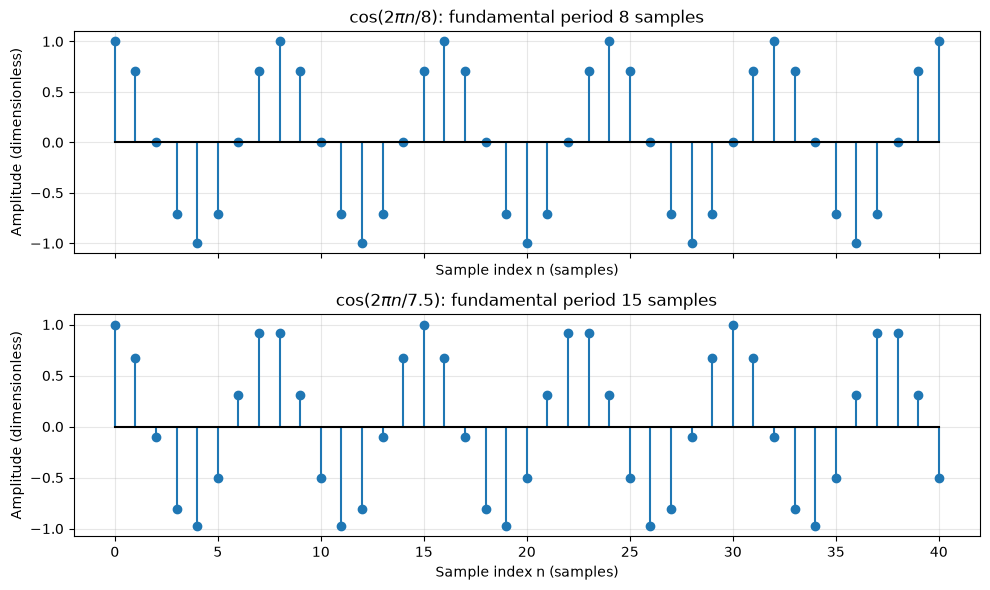

Verified fundamental periods: 8 samples and 15 samples.


In [4]:
n_cos = np.arange(41)
cos8 = np.cos(2 * np.pi * n_cos / 8)
cos75 = np.cos(2 * np.pi * n_cos / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, values, title in zip(
    axes, [cos8, cos75],
    [r'$\cos(2\pi n/8)$: fundamental period 8 samples',
     r'$\cos(2\pi n/7.5)$: fundamental period 15 samples'],
):
    ax.stem(n_cos, values, basefmt='k-')
    ax.set_title(title)
    ax.set_xlabel('Sample index n (samples)')
    ax.set_ylabel('Amplitude (dimensionless)')
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_2_cosines.png', dpi=160)
plt.show()

# Compare all overlapping samples separated by each proposed period.
assert np.allclose(cos8[8:], cos8[:-8], rtol=0, atol=1e-12)
assert np.allclose(cos75[15:], cos75[:-15], rtol=0, atol=1e-12)
assert not np.allclose(cos75[8:], cos75[:-8], rtol=0, atol=1e-12)
for samples, period in [(cos8, 8), (cos75, 15)]:
    assert not any(
        np.allclose(samples[k:], samples[:-k], rtol=0, atol=1e-12)
        for k in range(1, period)
    )
print('Verified fundamental periods: 8 samples and 15 samples.')

Both cosines are periodic. A discrete-time cosine repeats when
$\omega_0 N = 2\pi k$, where $N$ and $k$ are integers and $N>0$.

For $\cos(2\pi n/8)$, the smallest period is **8 samples**.
For $\cos(2\pi n/7.5)$, $1/7.5=2/15$, so the smallest period is
**15 samples**, covering two cycles. The second cosine cannot repeat
after 7.5 samples because its sample indices must be integers.
The checks above confirm both periods within floating-point tolerance.

## Task 1.3 — Working with audio

The supplied female synthetic voice says **“Hello, I'm Shemsa Amin.”**
It was generated with Microsoft Zira Desktop and saved as `my_voice.wav`:
48,000 Hz, mono, signed 16-bit PCM, 4.00 seconds including surrounding silence.
This is synthesized speech, rather than a phone recording of the student.
Keep `my_voice.wav` beside this notebook; in Colab, upload it to the Files panel.
The processed copy is saved as `outputs/lab0_processed.wav`.

Female synthetic voice: Hello, I'm Shemsa Amin. (Microsoft Zira Desktop)
fs = 48,000 Hz, duration = 4.00 s, samples = 192,000


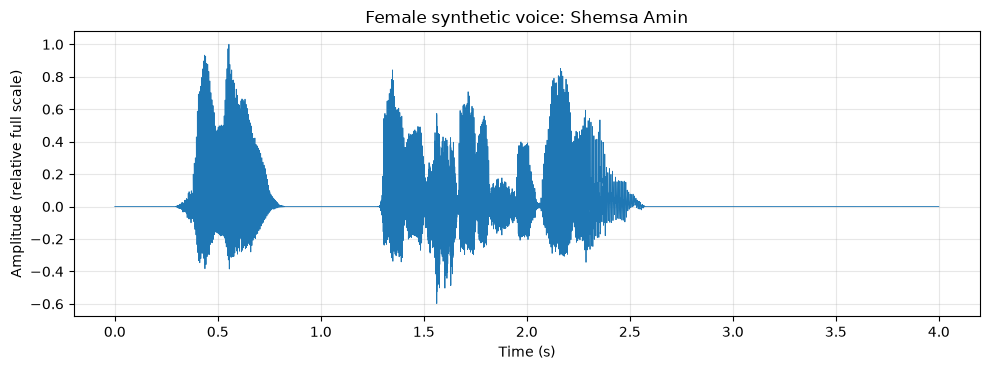

In [5]:
def mono_normalize(raw):
    raw = np.asarray(raw)
    values = raw.astype(np.float64)
    if raw.dtype == np.uint8:
        values -= 128
    if values.ndim == 2:
        values = values.mean(axis=1)
    if values.ndim != 1 or not values.size or not np.all(np.isfinite(values)):
        raise ValueError('Expected a nonempty, finite audio signal.')
    peak = np.max(np.abs(values))
    return values / peak if peak else values

fname = Path('my_voice.wav')
if not fname.is_file():
    raise FileNotFoundError('Place the supplied my_voice.wav beside this notebook (upload it in Colab).')
fs, raw = wavfile.read(fname)
x = mono_normalize(raw)
audio_source = "Female synthetic voice: Hello, I'm Shemsa Amin. (Microsoft Zira Desktop)"
t = np.arange(len(x)) / fs
duration = len(x) / fs
assert fs == 48000 and 3 <= duration <= 5
print(audio_source)
print(f'fs = {fs:,} Hz, duration = {duration:.2f} s, samples = {len(x):,}')
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t, x, linewidth=0.6)
ax.set(title='Female synthetic voice: Shemsa Amin', xlabel='Time (s)', ylabel='Amplitude (relative full scale)')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_3_audio.png', dpi=160)
plt.show()
display(Audio(x, rate=fs, normalize=False))

### Saving the audio

The signal is saved as a mono, 16-bit PCM WAV. Reading the file back
checks the sampling rate, sample count, and rounding error.

In [6]:
audio_out = output_dir / 'lab0_processed.wav'
pcm = np.rint(np.clip(x, -1, 1) * 32767).astype(np.int16)
wavfile.write(audio_out, fs, pcm)
fs_readback, pcm_readback = wavfile.read(audio_out)
assert fs_readback == fs
assert pcm_readback.shape == x.shape
assert np.array_equal(pcm_readback, pcm)
max_error = np.max(np.abs(x - pcm_readback.astype(float) / 32767))
assert max_error <= 0.5 / 32767 + 1e-12
print(f'Wrote {audio_out}: {fs_readback} Hz, mono, signed 16-bit PCM.')
print(f'Maximum write/read error = {max_error:.8f} (relative amplitude).')


assert np.array_equal(mono_normalize(np.zeros(8, dtype=np.int16)), np.zeros(8))
assert np.array_equal(mono_normalize(np.array([128, 128], dtype=np.uint8)), [0, 0])
assert np.allclose(mono_normalize(np.array([-32768, 0, 32767], dtype=np.int16)), [-1, 0, 32767/32768])
print('Normalization and WAV write/read checks passed.')

Wrote outputs\lab0_processed.wav: 48000 Hz, mono, signed 16-bit PCM.
Maximum write/read error = 0.00001526 (relative amplitude).
Normalization and WAV write/read checks passed.


The voice clip contains **192,000 samples** at **48,000 Hz**, lasting **4.00 seconds**.
The waveform contains speech bursts separated by pauses. It has no single 440 Hz
frequency or exponential envelope; the earlier fallback-tone description no longer applies.

## Task 1.4 - Octave (optional)

`week01_lab0.m` plots the same four sequences. NumPy uses `**` for
powers and `*` for element-wise array multiplication; Octave uses
`.^` and `.*`. The range `np.arange(-5, 11)` becomes `-5:10`.

Run `run('week01_lab0.m')` in Octave or MATLAB. This optional script
has not been executed in either application.

## Task 1.5 - Git repository

[Shemsanofly/COU07506-labs](https://github.com/Shemsanofly/COU07506-labs)

Mini-project topics proposed for group discussion:

1. Speech noise reduction using digital filters.
2. Detecting abnormal machine vibration from recorded sensor signals.

## Analysis questions

### 1. Sampling rate and storage for one minute

The supplied synthesized WAV is sampled at **48,000 Hz**. A phone recording's rate
has not been measured. One minute in mono requires $60f_s$ = **2,880,000 sample values**.
Signed 16-bit PCM uses **5,760,000 bytes** of sample data, excluding the WAV header.
The next cell derives these values from the loaded file.

In [7]:
one_minute_samples = 60 * int(fs)
one_minute_pcm_bytes = 2 * one_minute_samples
print(f'Audio source: {audio_source}')
print(f'Sampling rate: {fs:,} Hz')
print(f'One minute in mono: {one_minute_samples:,} sample values')
print(f'At 16-bit PCM: {one_minute_pcm_bytes:,} bytes of sample data (without WAV header)')

Audio source: Female synthetic voice: Hello, I'm Shemsa Amin. (Microsoft Zira Desktop)
Sampling rate: 48,000 Hz
One minute in mono: 2,880,000 sample values
At 16-bit PCM: 5,760,000 bytes of sample data (without WAV header)


### 2. Why use a stem plot for $x(n)$?

A discrete-time sequence has values only at integer indices. A stem
plot shows those individual samples. A continuous line would suggest
values between the samples, which are not part of the sequence.

### 3. Which property would $h(n)=(1.1)^n u(n)$ violate?

An LTI system with this impulse response would violate **BIBO stability**.
Its impulse response is not absolutely summable:
$\sum_{n=0}^{\infty}1.1^n$ diverges. A unit impulse is a bounded input,
but the resulting output $h(n)$ grows without bound.

## AI-use statement

**AI tool used:** ChatGPT (OpenAI).  
**Used for:** adapting the Week 1 sample, Python and Octave code, explanations, repository packaging, and documenting the female synthetic voice created with Windows speech synthesis.  
**Verification:** checked elementary sequence values, cosine periods of 8 and 15 samples, voice sample rate and duration, amplitude normalization, and WAV write/read accuracy. The optional Octave script has not been run in Octave/MATLAB. The notebooks were executed from top to bottom using Python. Automated checks do not replace the student's review or instructor sign-off.

[ ] I have reviewed the work and can explain every submitted line of code.